# Phase 3 — Realism and Kepler's problem

Tycho gains realistic noise (outliers, bias, drift, AR(1), heteroscedastic, clock errors),
seasonal schedules, hyperbolic and long-period bodies, and the knowledge tiers T2 (the
observer's orbit unknown, only a Sun stream published) and T3 (nothing about the observer).
Jan gains robust likelihoods, free observer parameters, and `kepler.triangulate` — Kepler's
own method: pair observations one period apart (the body is in the same place, the observer
is not) and intersect the lines of sight. Sweeps: `bench/kepler_problem.yaml`,
`bench/hyperbolic_comet.yaml`, `bench/sedna_like.yaml`, `bench/outliers_and_bias.yaml`.

In [1]:
import os, warnings
os.chdir('/home/dylan/Projects/jan-and-tycho')
os.environ.setdefault("MPLBACKEND", "Agg")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from pathlib import Path
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 160)

from IPython.display import Video
def results(name):
    p = Path("runs/sweeps") / name / "results.parquet"
    if not p.exists():
        print(f"(missing) run: jt bench sweep bench/{name}.yaml --workers 14 && jt bench report runs/sweeps/{name}")
        return None
    return pd.read_parquet(p)
def show(name, fig, width=760):
    p = Path("runs/sweeps") / name / "figures" / fig
    display(Image(filename=str(p), width=width)) if p.exists() else print(f"(missing figure {p})")
def cell_fig(name, scenario, label, fig, seed=0, width=760):
    """A per-run figure (or MP4) from a sweep cell."""
    p = Path("runs/sweeps") / name / "cells" / scenario / "base" / str(seed) / "rudolf" / label / "figures" / fig
    if not p.exists():
        print(f"(missing figure {p})")
    elif p.suffix == ".mp4":
        display(Video(str(p), embed=True, width=width))
    else:
        display(Image(filename=str(p), width=width))

## Acceptance 1 — `mars_unknown_earth` (T2): recover the Earth's orbit and Mars's

Criterion: Earth's e within 0.005 and Mars's a within 1 % by at least one strategy. With the
observer unknown, `kepler.triangulate` first solves Kepler's "reverse trick" (Earth's
positions from Mars sightings one Mars period apart, one unknown scale per group, tied
together by a single Keplerian observer orbit), then triangulates Mars and refines everything
against all observations.

In [2]:
df = results("kepler_problem")
if df is not None:
    d = df[df.status == "ok"].copy()
    d["|Δe| Earth"] = d["observer.err_e"].abs(); d["|Δa|/a Mars"] = d["err_a_rel"].abs()
    tab = d.groupby("label")[["|Δe| Earth", "|Δa|/a Mars", "holdout_rms_arcsec"]].median()
    display(tab.style.format("{:.2e}"))
    ok = d.groupby("label").apply(lambda g: ((g["|Δe| Earth"] < 0.005) & (g["|Δa|/a Mars"] < 0.01)).mean())
    print("fraction of seeds meeting both criteria:"); print(ok.round(2).to_string())

,|Δe| Earth,|Δa|/a Mars,holdout_rms_arcsec
label,,,
bayes.mcmc,7.01e-06,3.31e-07,6.10e+00
classical.lsq,9.35e-06,2.18e-07,7.05e+00
kepler.triangulate,7.10e-06,3.83e-07,6.13e+00
ptolemy.fourier,nan,nan,2.86e+01


fraction of seeds meeting both criteria:
label
bayes.mcmc            1.0
classical.lsq         1.0
kepler.triangulate    1.0
ptolemy.fourier       0.0


The triangulation animation shows the observer's orbit and then the body's being reconstructed:

In [3]:
cell_fig("kepler_problem", "mars_unknown_earth", "kepler.triangulate", "triangulation_animation.mp4")

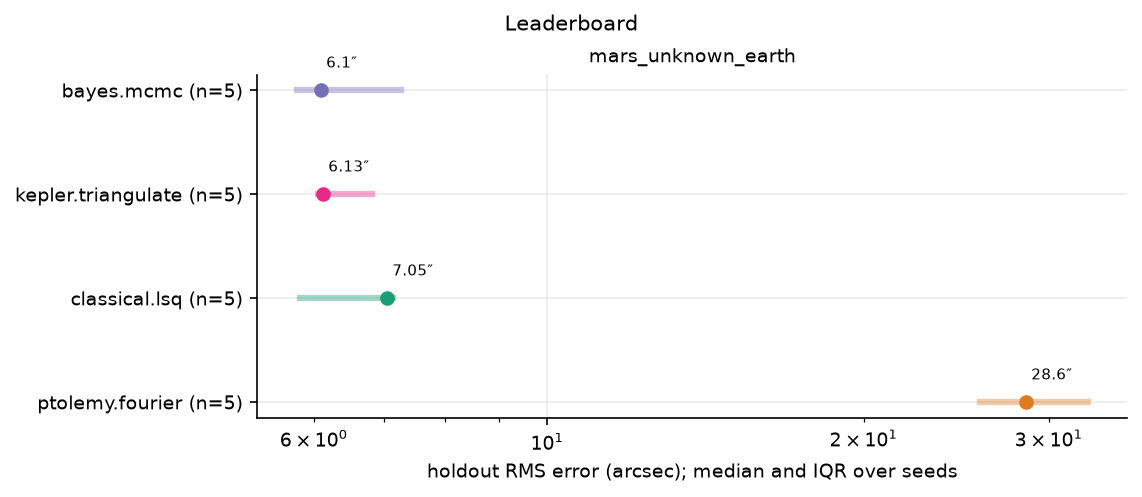

In [4]:
show("kepler_problem", "leaderboard.png")

## Acceptance 2 — `hyperbolic_comet`: nested sampling prefers e > 1

In [5]:
df = results("hyperbolic_comet")
if df is not None:
    d = df[(df.strategy == "bayes.nested") & (df.status == "ok")]
    display(d[["seed", "selected_family", "p_conic-hyperbolic", "p_conic-elliptic", "err_e"]])
    print(f"P(e > 1) ≥ 0.95 in {(d['p_conic-hyperbolic'] > 0.95).sum()} of {len(d)} seeds (min {d['p_conic-hyperbolic'].min():.4f})")

,seed,selected_family,p_conic-hyperbolic,p_conic-elliptic,err_e
0,0,conic-hyperbolic,1.0,0.0,-0.000024
3,1,conic-hyperbolic,1.0,0.0,0.000280
6,2,conic-hyperbolic,1.0,0.0,0.000003
9,3,conic-hyperbolic,1.0,0.0,-0.000037
12,4,conic-hyperbolic,1.0,0.0,-0.000152


P(e > 1) ≥ 0.95 in 5 of 5 seeds (min 1.0000)


## Acceptance 3 — `sedna_like`: a short arc of a distant body

Twenty years of a 10,000-year orbit: the arc constrains the position and the curvature of
the path but barely the period, so a and e are degenerate along a curved ridge (corner
plot). Coverage is measured over 20 seeds.

**How it is met.** In the family's coordinates φ = (log a, e, ϖ, cos i, Ω, λ0) the
posterior is a thin curved banana. The Laplace approximation (`classical.lsq`) puts a
Gaussian on it and NumPyro's NUTS (`bayes.hmc`, as configured) and emcee in φ
(`bayes.mcmc[coords=phi]`) do not traverse it: emcee's autocorrelation time there is
~2,000 steps (acceptance 0.09), and even 20,000-step chains with 64 walkers covered the
truth at 95 % in only 10–11 of 20 seeds for q, e, ω and t_p. The fix is a change of
coordinates, not a longer chain: `bayes.mcmc[coords=state]` samples the same posterior in
the heliocentric state (x, v) at the mid-arc epoch (prior carried over by the Jacobian),
where a short arc leaves mostly the range rate free along a nearly straight ridge. Its
autocorrelation time is ~75 steps and its 95 % intervals cover the truth. The other
strategies are kept in the table as a documented limitation.

In [6]:
df = results("sedna_like")
if df is not None:
    rows = []
    for lab, g in df[df.status == "ok"].groupby("label"):
        for el in ["q", "e", "i", "Omega", "omega", "t_p"]:
            if f"in95_{el}" in g:
                rows.append({"strategy": lab, "element": el, "cover68": g[f"in68_{el}"].dropna().astype(float).mean(), "cover95": g[f"in95_{el}"].dropna().astype(float).mean()})
    cov = pd.DataFrame(rows)
    display(cov.pivot(index="element", columns="strategy", values="cover95").round(2))

strategy,bayes.hmc,bayes.mcmc[coords=phi],bayes.mcmc[coords=state],classical.lsq
element,,,,
Omega,0.35,1.00,1.00,0.70
e,0.00,0.35,0.95,0.00
i,0.45,1.00,1.00,0.75
omega,0.00,0.35,0.95,0.00
q,0.00,0.35,0.95,0.00
t_p,0.00,0.35,0.95,0.00


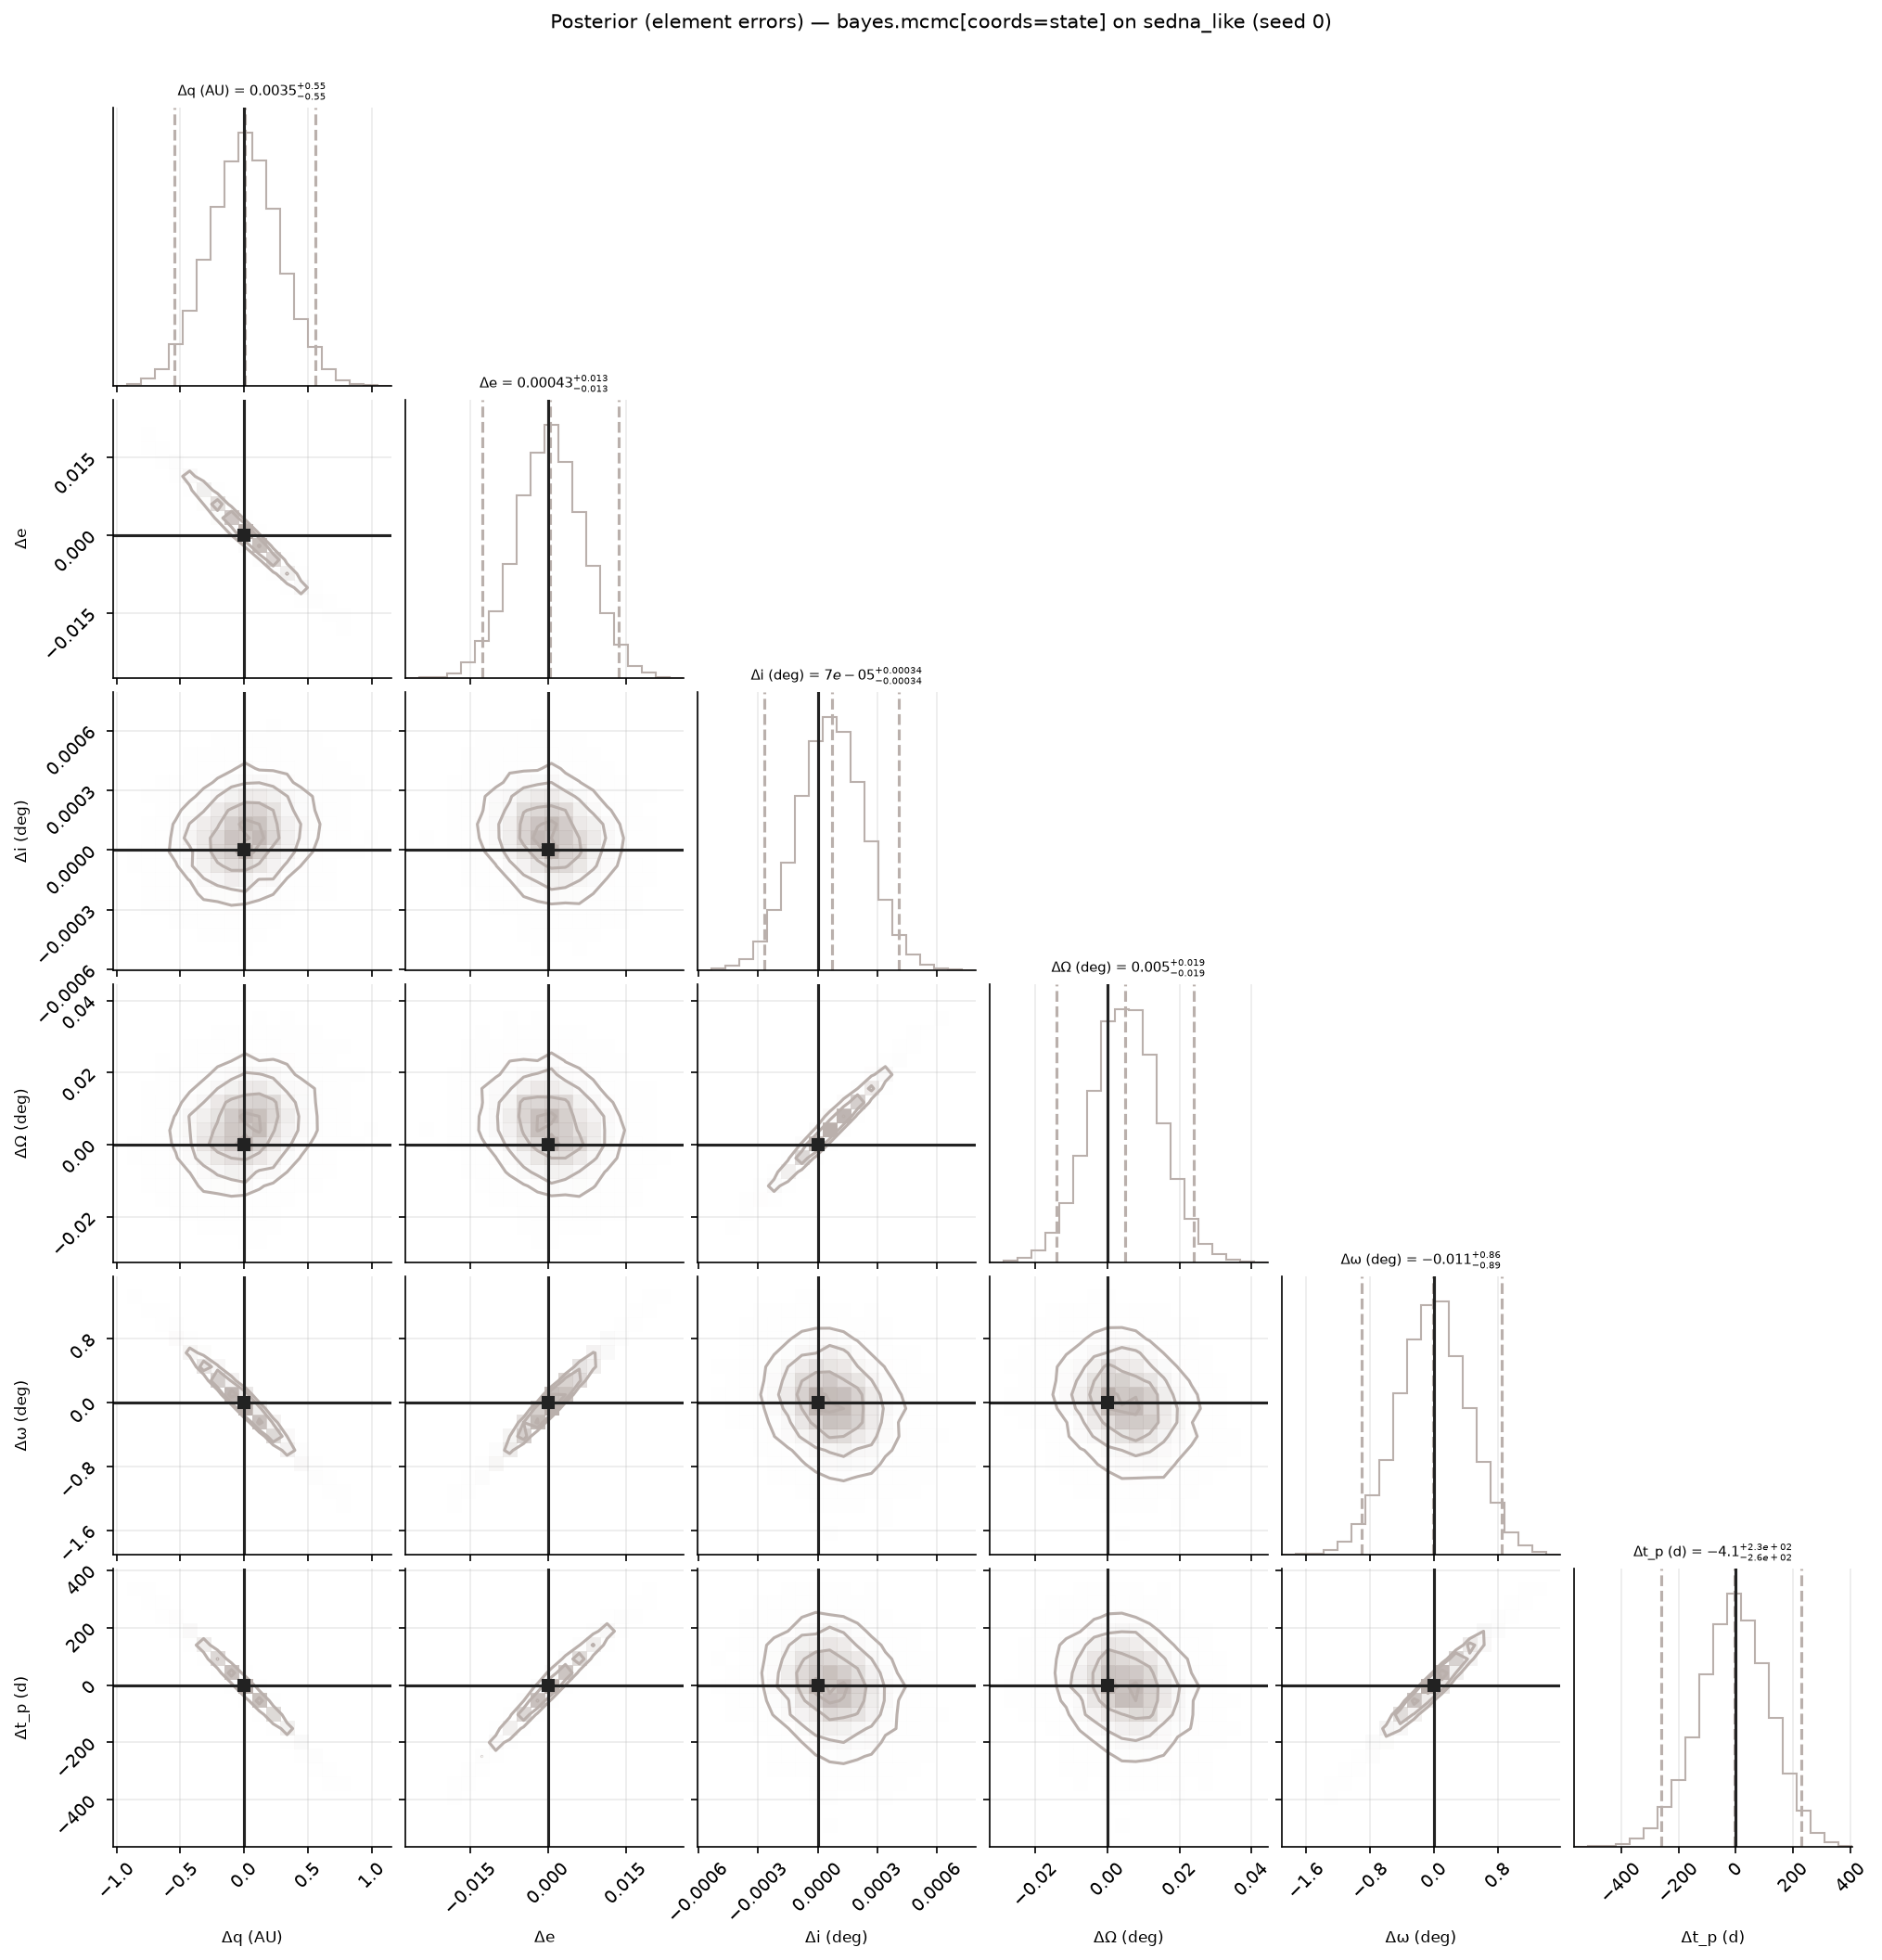

In [7]:
cell_fig("sedna_like", "sedna_like", "bayes.mcmc[coords=state]", "corner.png", width=700)

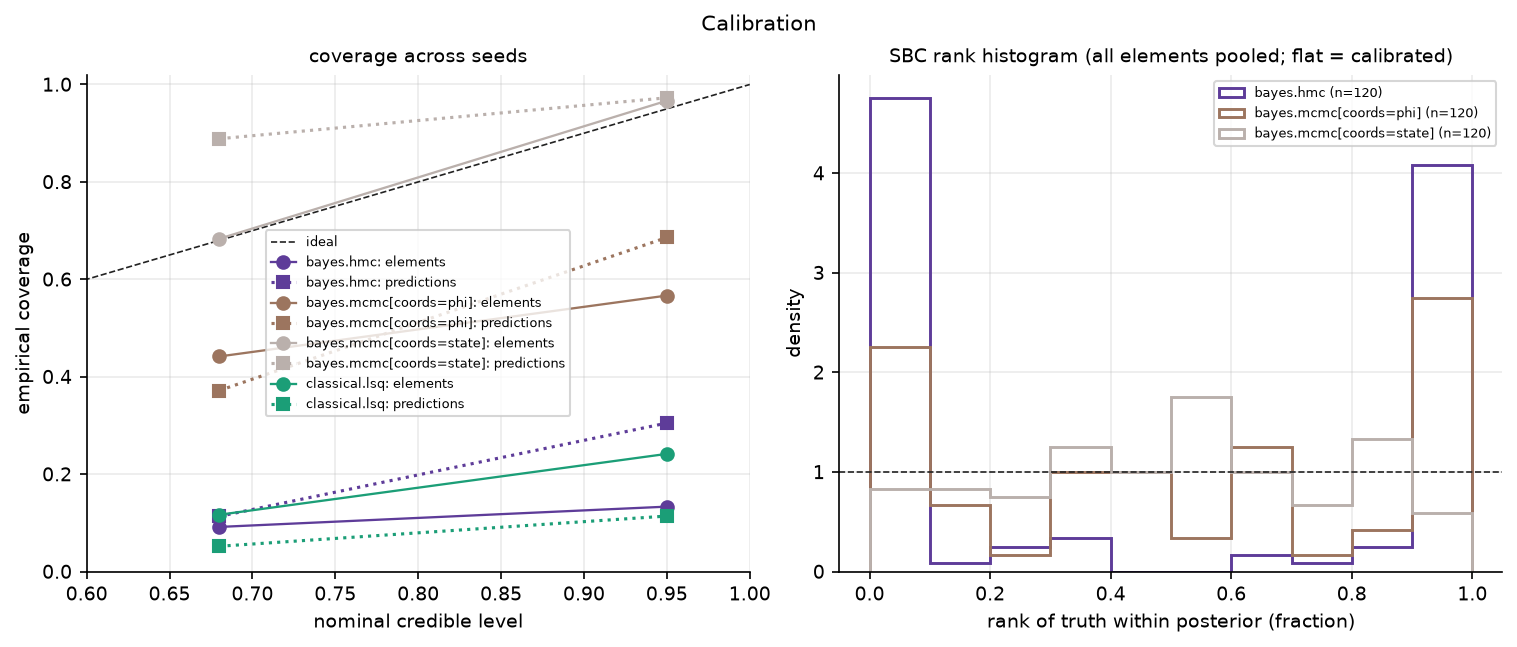

In [8]:
show("sedna_like", "calibration.png", 900)

## Acceptance 4 — `outliers_and_bias`: robust likelihoods

5 % of the observations are 2° outliers and there is a 10″ systematic bias. Criterion: the
robust likelihood cuts holdout RMS by ≥ 2× relative to the Gaussian one.

In [9]:
df = results("outliers_and_bias")
if df is not None:
    d = df[df.status == "ok"]
    tab = d.groupby("label")["holdout_rms_arcsec"].median()
    display(tab.round(1).to_frame("median holdout RMS (″)"))
    for g, r in [("bayes.mcmc[likelihood=gaussian]", "bayes.mcmc[likelihood=student_t]"), ("classical.lsq[loss=linear]", "classical.lsq[loss=cauchy]")]:
        if g in tab and r in tab:
            print(f"{r}: {tab[g] / tab[r]:.1f}× lower than {g} (criterion ≥ 2×)")

,median holdout RMS (″)
label,
bayes.mcmc[likelihood=gaussian],236.1
bayes.mcmc[likelihood=student_t],6.8
classical.lsq[loss=cauchy],6.8
classical.lsq[loss=linear],234.6


bayes.mcmc[likelihood=student_t]: 34.5× lower than bayes.mcmc[likelihood=gaussian] (criterion ≥ 2×)
classical.lsq[loss=cauchy]: 34.6× lower than classical.lsq[loss=linear] (criterion ≥ 2×)


`noise_diagnostics` marks the true outliers (sealed) and the ones the robust fit down-weights:

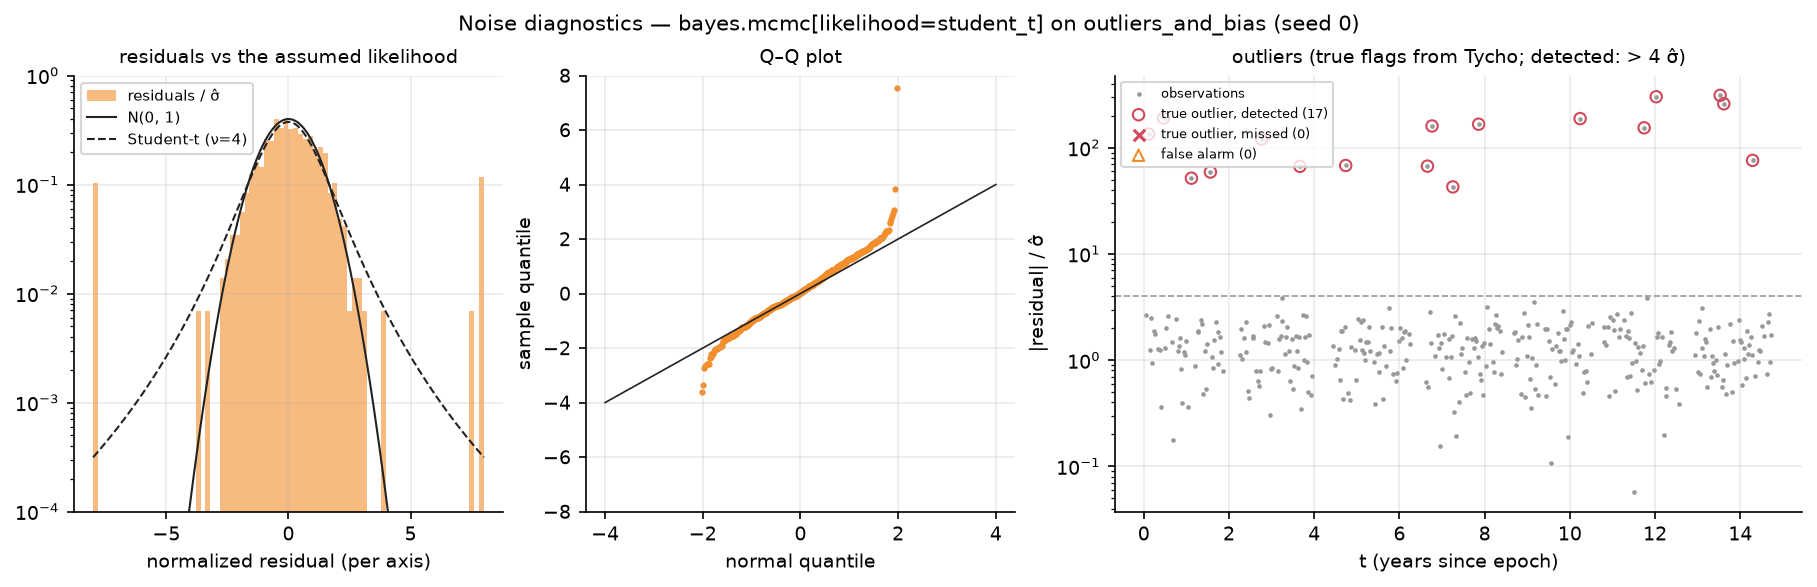

In [10]:
cell_fig("outliers_and_bias", "outliers_and_bias", "bayes.mcmc[likelihood=student_t]", "noise_diagnostics.png", width=900)